<a href="https://colab.research.google.com/github/muhammadyusuf-pro/Machine-Learning-Course/blob/main/XGBoosting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [43]:
from xgboost import XGBClassifier
import pandas as pd
from zipfile import ZipFile
from io import BytesIO
from urllib.request import urlopen
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

URL = ('https://archive.ics.uci.edu/static/public/222/bank+marketing.zip')

outer = ZipFile(BytesIO(urlopen(URL).read()))
inner = ZipFile(BytesIO(outer.read('bank-additional.zip')))
df = pd.read_csv(
    inner.open('bank-additional/bank-additional.csv'),sep=";"
)
df.to_csv('bank.csv',sep=";", index=False)

df.head()

y = df["y"].map({"no": 0, "yes": 1})
X = df.drop(columns=["y"])

# Matnli ustunlarni raqamga aylantirdik
X = pd.get_dummies(X, drop_first=True)

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

def train(lr, Xtr=X_train, ytr=y_train, Xva=X_valid, yva=y_valid, patience=50):
  model = XGBClassifier(n_estimators = 2000, learning_rate = lr, max_depth = 3, early_stopping_rounds=patience, eval_metric = "logloss", random_state=42)
  model.fit(Xtr, ytr, eval_set = [(Xtr, ytr), (Xva, yva)], verbose = False)

  pred = model.predict(X_test)
  print("Accuracy: ", round(accuracy_score(y_test, pred), 4))
  print("Best iteration: ", model.best_iteration)
  print("Best score: ", model.best_score)
  return model

model = train(0.3)

Accuracy:  0.9114
Best iteration:  50
Best score:  0.1832040031566296


{'validation_0': OrderedDict({'logloss': [0.25460100985342843, 0.22738321800612574, 0.21156448388765428, 0.2003265680908819, 0.19177155226065, 0.18594107146023234, 0.18227057317019305, 0.17787990872855614, 0.1751059120304608, 0.17237071966573758, 0.1693340962824688, 0.16700760962894598, 0.16492847132073277, 0.1634285619219698, 0.16134055188588664, 0.15980364275123443, 0.15840172609227635, 0.15662413584198448, 0.15444407303549404, 0.1529662759001676, 0.1508171021657674, 0.1498451323094105, 0.14854775974736653, 0.14791961131030026, 0.1471781565621712, 0.14604327269787737, 0.14510325229616158, 0.14471495081614047, 0.14302435409803596, 0.14210644504682568, 0.14148003733211387, 0.1395676913000194, 0.13831782451155702, 0.13723292981413243, 0.13687463995335664, 0.1360851462272937, 0.13458215859592712, 0.13261097598658056, 0.1319782398345301, 0.13139915949261985, 0.13089165676758344, 0.130249481172799, 0.12837048937976434, 0.12778153316046825, 0.1273097327168852, 0.12660362703936978, 0.1258228

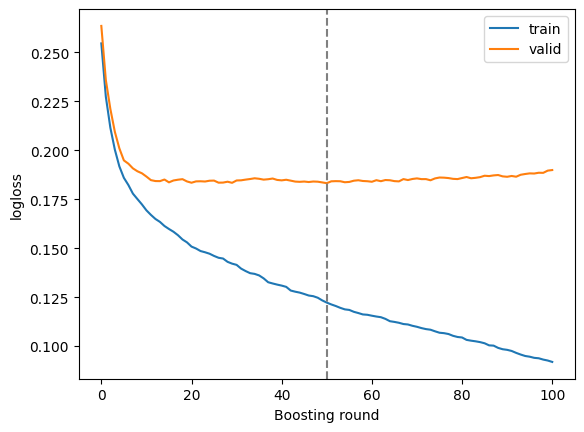

In [44]:
import matplotlib.pyplot as plt
res = model.evals_result()
print(res)
plt.plot(res["validation_0"]["logloss"], label="train")
plt.plot(res["validation_1"]["logloss"], label="valid")
plt.axvline(model.best_iteration, ls="--", color="gray")
plt.xlabel("Boosting round")
plt.ylabel("logloss")
plt.legend()
plt.show()

              feature  importance
9         nr.employed    0.631873
1            duration    0.041535
52   poutcome_success    0.025480
37  contact_telephone    0.020751
47    day_of_week_mon    0.016759
3               pdays    0.014790
48    day_of_week_thu    0.014437
43          month_may    0.013556
8           euribor3m    0.012608
31    default_unknown    0.012473


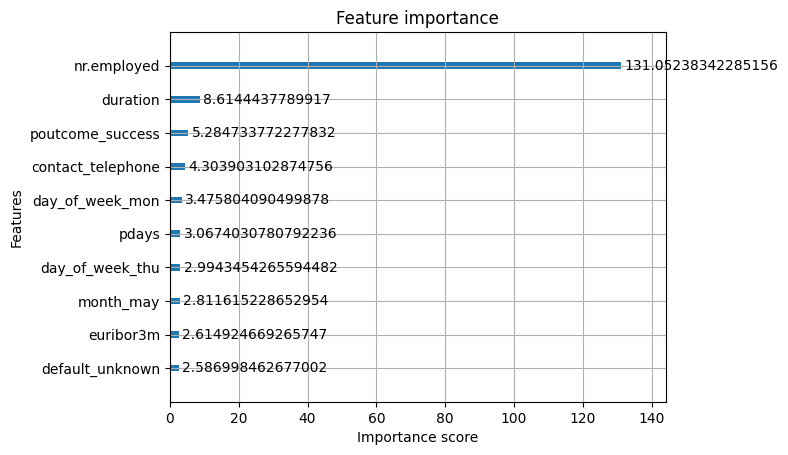

In [56]:
from xgboost import plot_importance
import matplotlib.pyplot as plt

importances = model.feature_importances_
import_df = pd.DataFrame({"feature": X_train.columns, "importance": model.feature_importances_}).sort_values("importance", ascending=False)
print(import_df.head(10))

plot_importance(model, importance_type="gain", max_num_features=10)
plt.show()